In [1]:
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
import os
load_dotenv()


True

In [ ]:
llm= ChatOpenAI(
    model="openai/gpt-oss-120b",
    api_key=os.getenv('GROQ_API_KEY'),
    base_url= "https://api.groq.com/openai/v1",
    max_tokens= 1000
)

In [3]:
from typing import TypedDict
class PortfolioState(TypedDict):
    amount_usd: float
    total_usd: float
    total_inr: float

def calc_total(state: PortfolioState) -> PortfolioState:
   state['total_usd'] = state['amount_usd'] * 1.08 # Assuming 1 USD = 1 USD for simplicity
   return state

def convert_to_inr(state: PortfolioState) -> PortfolioState:
   state['total_inr'] = state['total_usd'] * 94 # Assuming 1 USD = 94 INR for simplicity
   return state


In [4]:
from langgraph.graph import StateGraph,START,END

builder= StateGraph(PortfolioState)

builder.add_node("calc_total_node",calc_total)
builder.add_node("calc_total_inr_node",convert_to_inr)

builder.add_edge(START,"calc_total_node")
builder.add_edge("calc_total_node","calc_total_inr_node")
builder.add_edge("calc_total_inr_node",END)

graph= builder.compile()

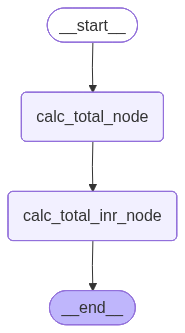

In [5]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))


In [7]:
graph.invoke({"amount_usd": 1})

{'amount_usd': 1, 'total_usd': 1.08, 'total_inr': 101.52000000000001}